# Neural Process

Una capa nueva (AttnLNP) sobre SEED congelado, entrenada por fold, con validación sin etiquetas y evaluación con la costura de 20 s / 10 s. 16 muestras de la variable latente. Su incertidumbre es aprendida y su escala no es directamente comparable con la de los métodos bayesianos.


**Datos.** Evaluaciones 0, 1 y 2, cinco folds de test cada una (15 folds en total). Se leen los `test_predictions.npz` ya guardados: el notebook no entrena ni vuelve a inferir. Todo se calcula sobre los timesteps válidos.

**Cómo leer las tablas.** Cada tabla muestra *media ± desviación estándar* entre folds para cada evaluación (0, 1 y 2) y el promedio de las tres (los 15 folds juntos). Los gráficos tienen cuatro paneles con las mismas cuatro vistas.

**Definiciones que se repiten**

- *Cerca de eventos*: ±1 s alrededor de un huso real o predicho. Es donde ocurren los errores; el ~92% restante es fondo fácil que infla los AUROC.
- *Azar*: 0.5 para un AUROC; para un AUPRC, la proporción de positivos (tasa de error o proporción de FP/FN).
- *Aleatoria* = entropía esperada (ambigüedad de la señal); *epistémica* = MI (desacuerdo entre muestras del modelo); *total* = entropía predictiva = aleatoria + MI.
- *SEED H(p)*: la incertidumbre del SEED original sobre los mismos timesteps o eventos, como referencia.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

METHOD = 'Neural Process'
REFRESH = False  # True recalcula desde los NPZ (varios minutos)
results = report.method_results(METHOD, refresh=REFRESH)
metrics = results['metrics']

Neural Process: evaluación 0 lista
Neural Process: evaluación 1 lista
Neural Process: evaluación 2 lista


## 1. Detección y calibración

F1, precisión y recall por evento (IoU ≥ 0.2, métrica principal), AUROC/AUPRC de detección por timestep y calidad de la probabilidad (NLL, Brier y ECE de la clase positiva; menor es mejor).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
F1 evento (%),83.42 ± 0.92,83.29 ± 0.72,83.31 ± 1.2,83.34 ± 0.92
precisión (%),84.58 ± 3.6,84.73 ± 2.5,86.18 ± 2.3,85.16 ± 2.7
recall (%),82.47 ± 3.1,81.98 ± 1.9,80.73 ± 3.2,81.73 ± 2.7
AUROC detección,0.991 ± 0.00088,0.9903 ± 0.0014,0.991 ± 0.00022,0.9908 ± 0.00096
AUPRC detección,0.8889 ± 0.011,0.8879 ± 0.0042,0.8872 ± 0.012,0.888 ± 0.0091
NLL,0.05412 ± 0.0061,0.05652 ± 0.0041,0.05459 ± 0.0045,0.05508 ± 0.0047
Brier,0.01484 ± 0.0015,0.01496 ± 0.00071,0.01492 ± 0.00089,0.0149 ± 0.001
ECE clase positiva,0.006257 ± 0.0018,0.006806 ± 0.00084,0.00673 ± 0.0022,0.006598 ± 0.0016


F1 evento (%)  precisión (%)  recall (%)  AUROC detección  AUPRC detección     NLL   Brier  ECE clase positiva
evaluación fold                                                                                                                
0          0           84.1535        83.5777     84.7374           0.9918           0.8938  0.0497  0.0139              0.0045
           1           81.8263        81.8996     81.7531           0.9896           0.8708  0.0646  0.0172              0.0092
           2           83.6946        82.2222     85.2207           0.9913           0.8869  0.0515  0.0147              0.0055
           3           83.8624        84.5333     83.2021           0.9910           0.8994  0.0544  0.0153              0.0058
           4           83.5430        90.6712     77.4538           0.9916           0.8938  0.0504  0.0131              0.0063
1          0           83.0084        83.0084     83.0084           0.9913           0.8868  0.0529  0.0145              0.0070
           1           84.2744        84.4715     84.0782           0.9920           0.8943  0.0542  0.0147              0.0071
           2           82.9193        85.5769     80.4217           0.9901           0.8852  0.0538  0.0142              0.0056
           3           82.4771        82.0255     82.9336           0.9892           0.8836  0.0597  0.0159              0.0078
           4           83.7607        88.5542     79.4595           0.9887           0.8897  0.0621  0.0155              0.0065
2          0           81.6348        86.8943     76.9756           0.9909           0.8766  0.0515  0.0147              0.0058
           1           84.2466        82.8283     85.7143           0.9908           0.9002  0.0594  0.0158              0.0092
           2           82.5182        85.3606     79.8590           0.9910           0.8751  0.0538  0.0147              0.0067
           3           83.4419        86.6667     80.4484           0.9910           0.8847  0.0590  0.0157              0.0082
           4           84.6954        89.1554     80.6604           0.9914           0.8993  0.0492  0.0136              0.0037

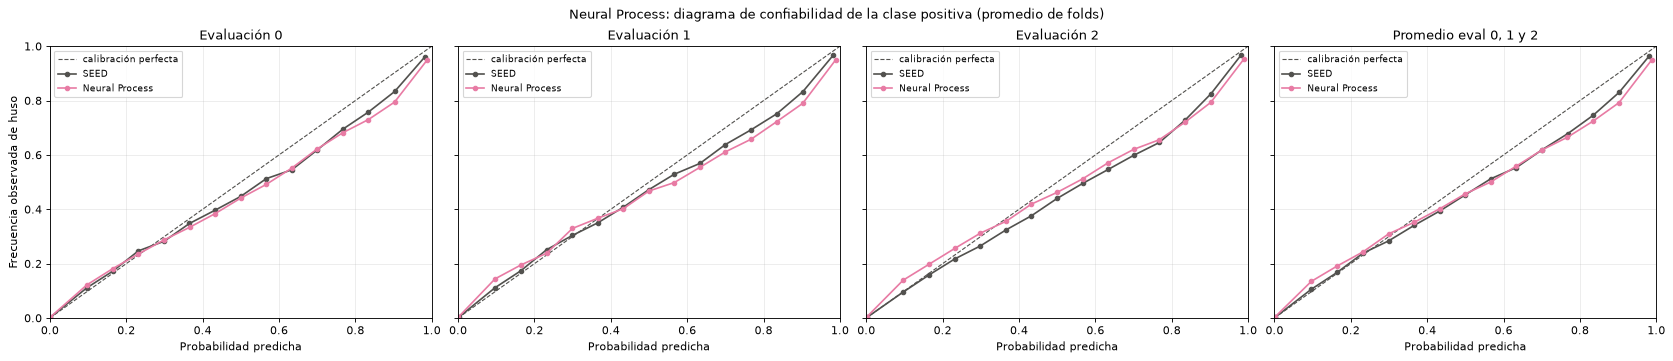

In [2]:
DETECTION = ['F1 evento (%)', 'precisión (%)', 'recall (%)', 'AUROC detección', 'AUPRC detección', 'NLL', 'Brier', 'ECE clase positiva']
display(report.by_evaluation(metrics, DETECTION))
display(metrics.set_index(['evaluación', 'fold'])[DETECTION].round(4))
show(report.plot_reliability(results, METHOD))

## 2. Curvas ROC

Curva promedio de los folds. *Detección*: huso vs fondo con la probabilidad. *Errores*: timesteps mal clasificados vs bien clasificados cerca de eventos, ordenados por cada medida de incertidumbre.

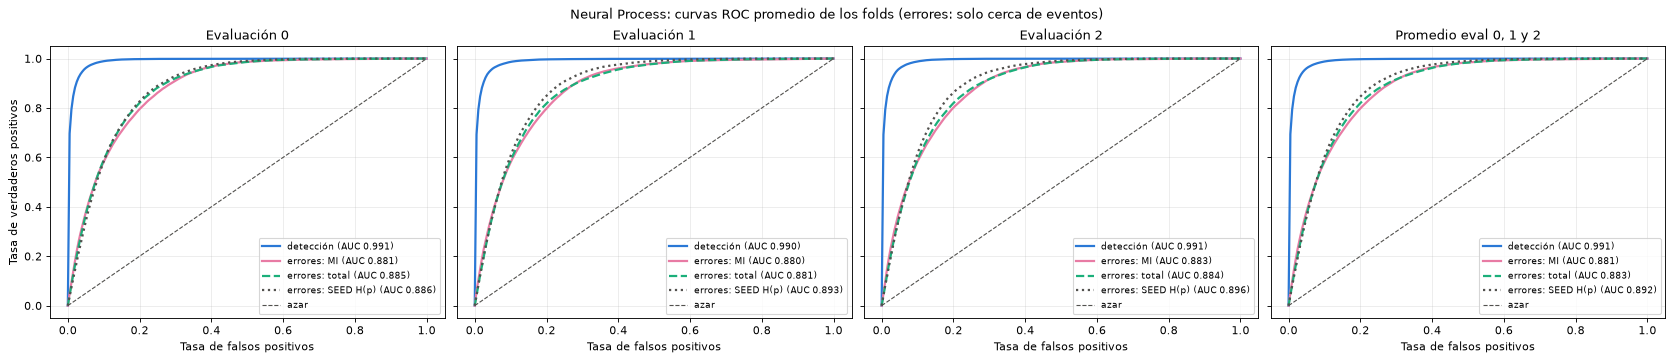

In [3]:
show(report.plot_roc(results, METHOD))

## 3. Descomposición de la incertidumbre

Entropía media en bits, en todo el registro y cerca de eventos, separada en aleatoria y epistémica (MI), con la incertidumbre de SEED como referencia.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
total (registro),0.05035 ± 0.0079,0.04649 ± 0.0023,0.04789 ± 0.0042,0.04824 ± 0.0052
aleatoria (registro),0.03724 ± 0.0072,0.03388 ± 0.0027,0.03513 ± 0.0028,0.03542 ± 0.0046
SEED H(p) (registro),0.06025 ± 0.0091,0.05881 ± 0.0089,0.06412 ± 0.006,0.06106 ± 0.0079
MI (registro),0.01311 ± 0.0041,0.01261 ± 0.0046,0.01276 ± 0.0027,0.01283 ± 0.0036
% epistémica (registro),26.24 ± 7.9,26.81 ± 9.2,26.49 ± 4.5,26.52 ± 6.9
total (cerca de eventos),0.2053 ± 0.021,0.1962 ± 0.0061,0.1989 ± 0.015,0.2001 ± 0.015
aleatoria (cerca de eventos),0.1579 ± 0.02,0.15 ± 0.012,0.1526 ± 0.0099,0.1535 ± 0.014
SEED H(p) (cerca de eventos),0.2255 ± 0.0073,0.2264 ± 0.025,0.2315 ± 0.0089,0.2278 ± 0.015
MI (cerca de eventos),0.04738 ± 0.015,0.04613 ± 0.017,0.04636 ± 0.0096,0.04663 ± 0.013
% epistémica (cerca de eventos),23.08 ± 7,23.36 ± 8.1,23.19 ± 3.9,23.21 ± 6.1


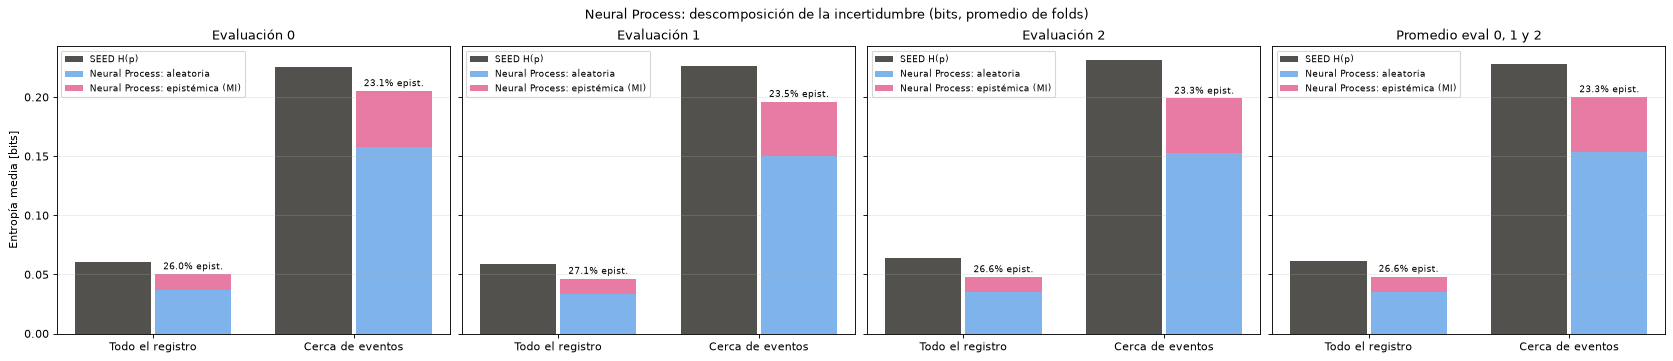

In [4]:
DECOMPOSITION = [c for c in metrics.columns if c.endswith('(registro)') or c.endswith('(cerca de eventos)')]
display(report.by_evaluation(metrics, DECOMPOSITION))
show(report.plot_decomposition(results, METHOD))

## 4. ¿La incertidumbre detecta los errores?

Errores por timestep cerca de eventos: AUROC y AUPRC de cada medida. El AUPRC se compara con la tasa de error (azar).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
AUROC errores: total,0.8849 ± 0.0057,0.8808 ± 0.0093,0.8844 ± 0.0054,0.8833 ± 0.0068
AUPRC errores: total,0.3992 ± 0.0065,0.4005 ± 0.01,0.4047 ± 0.019,0.4015 ± 0.012
AUROC errores: aleatoria,0.8658 ± 0.0046,0.863 ± 0.013,0.8662 ± 0.0027,0.865 ± 0.0077
AUPRC errores: aleatoria,0.3391 ± 0.017,0.3438 ± 0.015,0.3443 ± 0.0092,0.3424 ± 0.013
AUROC errores: SEED H(p),0.8864 ± 0.0073,0.8932 ± 0.0094,0.8958 ± 0.0037,0.8918 ± 0.0078
AUPRC errores: SEED H(p),0.387 ± 0.028,0.4111 ± 0.028,0.4145 ± 0.025,0.4042 ± 0.028
AUROC errores: MI,0.8814 ± 0.0069,0.8797 ± 0.0099,0.8833 ± 0.0064,0.8814 ± 0.0075
AUPRC errores: MI,0.4042 ± 0.022,0.414 ± 0.018,0.4164 ± 0.03,0.4115 ± 0.023
azar errores,0.1012 ± 0.0043,0.1028 ± 0.0033,0.1038 ± 0.0061,0.1026 ± 0.0045


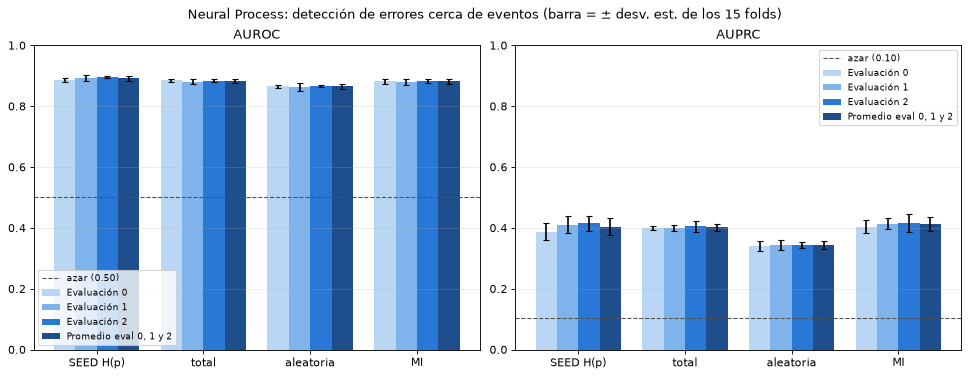

In [5]:
ERRORS = [c for c in metrics.columns if c.startswith('AUROC errores') or c.startswith('AUPRC errores')] + ['azar errores']
display(report.by_evaluation(metrics, ERRORS))
show(report.plot_error_detection(results, METHOD))

## 5. Dónde se concentra la incertidumbre

Entropía media por zona: bordes de los husos (±0.25 s del inicio o fin real), interior del huso y fondo.

Borde del huso
Interior del huso
Fondo


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,6.124 ± 0.34,6.124 ± 0.24,6.124 ± 0.36,6.124 ± 0.3
SEED H(p),0.4373 ± 0.015,0.4373 ± 0.033,0.4466 ± 0.014,0.4404 ± 0.021
aleatoria,0.337 ± 0.033,0.321 ± 0.027,0.3248 ± 0.015,0.3276 ± 0.025
MI,0.07529 ± 0.022,0.07295 ± 0.025,0.07353 ± 0.016,0.07392 ± 0.02


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,2.055 ± 0.25,2.055 ± 0.19,2.055 ± 0.2,2.055 ± 0.2
SEED H(p),0.2824 ± 0.076,0.2848 ± 0.057,0.2954 ± 0.066,0.2876 ± 0.062
aleatoria,0.1339 ± 0.017,0.1347 ± 0.025,0.1403 ± 0.036,0.1363 ± 0.025
MI,0.07469 ± 0.029,0.07286 ± 0.03,0.07724 ± 0.026,0.07493 ± 0.026


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,91.82 ± 0.53,91.82 ± 0.36,91.82 ± 0.55,91.82 ± 0.45
SEED H(p),0.03029 ± 0.011,0.02841 ± 0.0057,0.0336 ± 0.006,0.03076 ± 0.0077
aleatoria,0.01505 ± 0.0048,0.01245 ± 0.0019,0.01348 ± 0.0015,0.01366 ± 0.0031
MI,0.007664 ± 0.0028,0.007221 ± 0.0028,0.007342 ± 0.0022,0.007409 ± 0.0024


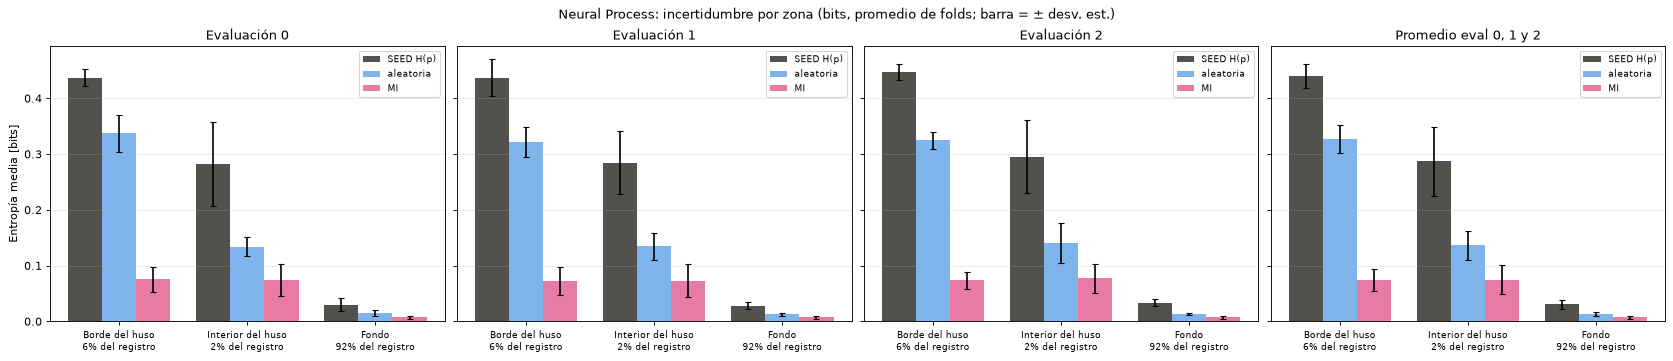

In [6]:
zones = results['zones']
for zone in ['Borde del huso', 'Interior del huso', 'Fondo']:
    print(zone)
    display(report.by_evaluation(zones[zones['zona'] == zone], [c for c in zones.columns if c not in ('evaluación', 'fold', 'zona')]))
show(report.plot_zones(results, METHOD))

## 6. Duración del evento vs incertidumbre

ρ es la correlación de Spearman entre la duración de cada evento predicho y su incertidumbre media (MI; para SEED, su entropía). ρ < 0: los eventos cortos son más inciertos.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
ρ duración-incertidumbre,-0.4951 ± 0.025,-0.5067 ± 0.067,-0.4786 ± 0.035,-0.4935 ± 0.044


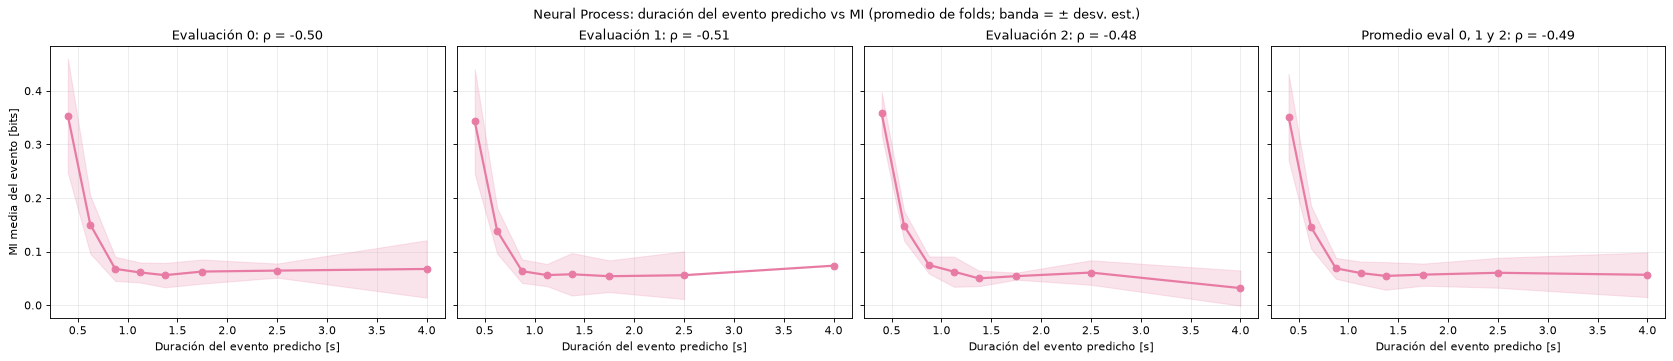

In [7]:
display(report.by_evaluation(metrics, ['ρ duración-incertidumbre']))
show(report.plot_duration(results, METHOD))

## 7. Aciertos, falsos positivos y falsos negativos

- **TP / FP (predicho)**: detecciones correctas y falsas, medidas en el tramo que el modelo predijo.
- **TP / FN (real)**: husos detectados y no detectados, medidos en el tramo real del huso (un FN no tiene tramo predicho). Los pares con IoU < 0.2 cuentan como FN, igual que en el F1.

Primero las medianas de cada medida, luego qué tan bien cada medida separa FP de TP y FN de TP (AUROC y AUPRC con su azar), y al final los gráficos de cajón en percentil dentro del fold, con la línea de azar en 0.5. Comparar la *probabilidad media* entre FN y TP es casi circular (un FN es justamente un tramo con probabilidad baja).

Medianas por tipo de evento
FP vs TP (tramo predicho)
FN vs TP (tramo real)


eval 0                                                                                           eval 1                                                                                           eval 2                      \
              probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total   
grupo                                                                                                                                                                                                                                                    
TP (predicho)             0.9000              0.3137    0.2820          0.0260                          0.0480             0.9025              0.3074    0.2735          0.0254                          0.0459             0.9031              0.3030   
FP (predicho)             0.6834              0.8648    0.4676          0.2638                          0.2611             0.6895              0.8579    0.4695          0.2722                          0.2675             0.7073              0.8380   
TP (real)                 0.8918              0.2919    0.2594          0.0210                          0.0405             0.8917              0.2796    0.2489          0.0205                          0.0387             0.8923              0.2764   
FN (real)                 0.1419              0.5060    0.2660          0.1793                          0.1721             0.1170              0.4528    0.2332          0.1847                          0.1683             0.1285              0.4606   

                                                                        promedio eval 0, 1 y 2                                                                                
              aleatoria epistémica (MI) dispersión entre muestras (std)     probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std)  
grupo                                                                                                                                                                         
TP (predicho)    0.2737          0.0244                          0.0450                 0.9017              0.3091    0.2764          0.0253                          0.0463  
FP (predicho)    0.4739          0.3108                          0.2791                 0.6942              0.8522    0.4703          0.2809                          0.2717  
TP (real)        0.2492          0.0204                          0.0380                 0.8919              0.2821    0.2528          0.0207                          0.0392  
FN (real)        0.2578          0.1826                          0.1728                 0.1289              0.4716    0.2512          0.1816                          0.1718

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1542 ± 0.036,0.1527 ± 0.025,0.1382 ± 0.023,0.1484 ± 0.027
AUROC probabilidad media,0.8359 ± 0.022,0.8402 ± 0.014,0.8338 ± 0.026,0.8366 ± 0.02
AUPRC probabilidad media,0.4501 ± 0.081,0.438 ± 0.051,0.4001 ± 0.077,0.4294 ± 0.069
AUROC incertidumbre total,0.8453 ± 0.018,0.8481 ± 0.014,0.8426 ± 0.024,0.8453 ± 0.018
AUPRC incertidumbre total,0.4465 ± 0.089,0.4373 ± 0.058,0.4068 ± 0.079,0.4302 ± 0.073
AUROC aleatoria,0.816 ± 0.012,0.8287 ± 0.02,0.8228 ± 0.023,0.8225 ± 0.018
AUPRC aleatoria,0.4 ± 0.092,0.4136 ± 0.085,0.3619 ± 0.083,0.3918 ± 0.083
AUROC epistémica (MI),0.8296 ± 0.023,0.8311 ± 0.017,0.8311 ± 0.023,0.8306 ± 0.02
AUPRC epistémica (MI),0.4117 ± 0.078,0.4155 ± 0.048,0.374 ± 0.068,0.4004 ± 0.064
AUROC dispersión entre muestras (std),0.8359 ± 0.02,0.8379 ± 0.015,0.8351 ± 0.023,0.8363 ± 0.018


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1751 ± 0.031,0.1802 ± 0.019,0.1925 ± 0.032,0.1826 ± 0.027
AUROC probabilidad media,0.9604 ± 0.014,0.9642 ± 0.0092,0.9633 ± 0.03,0.9627 ± 0.019
AUPRC probabilidad media,0.9418 ± 0.021,0.9518 ± 0.006,0.9474 ± 0.039,0.947 ± 0.024
AUROC incertidumbre total,0.5887 ± 0.061,0.5544 ± 0.07,0.5672 ± 0.035,0.5701 ± 0.055
AUPRC incertidumbre total,0.2406 ± 0.014,0.233 ± 0.03,0.2458 ± 0.028,0.2398 ± 0.024
AUROC aleatoria,0.4783 ± 0.058,0.436 ± 0.079,0.465 ± 0.012,0.4598 ± 0.056
AUPRC aleatoria,0.1843 ± 0.024,0.182 ± 0.026,0.1914 ± 0.023,0.1859 ± 0.023
AUROC epistémica (MI),0.7167 ± 0.053,0.6897 ± 0.053,0.7091 ± 0.022,0.7051 ± 0.043
AUPRC epistémica (MI),0.3358 ± 0.042,0.3421 ± 0.053,0.3431 ± 0.052,0.3403 ± 0.046
AUROC dispersión entre muestras (std),0.6778 ± 0.062,0.6499 ± 0.061,0.667 ± 0.028,0.6649 ± 0.05


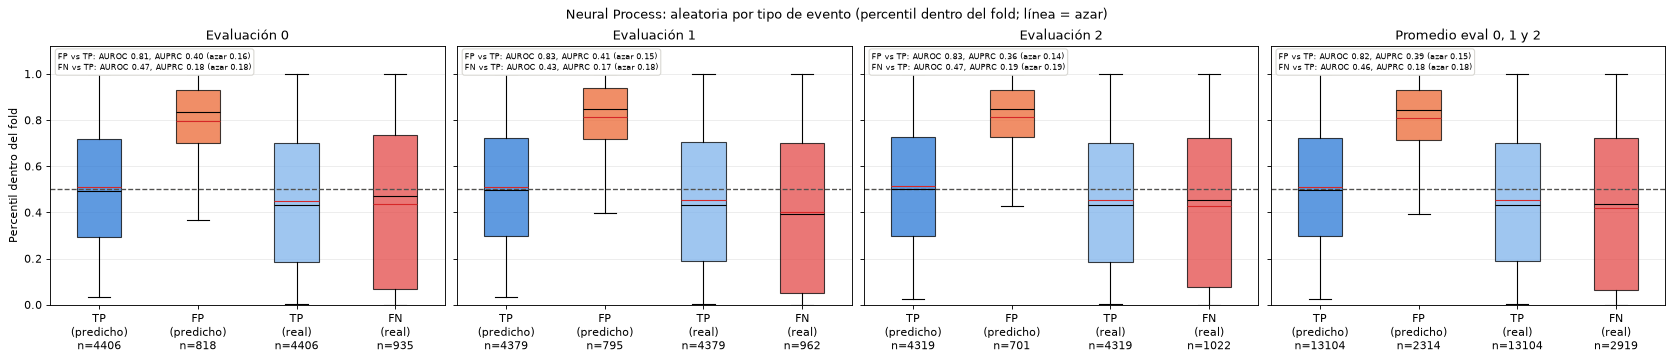

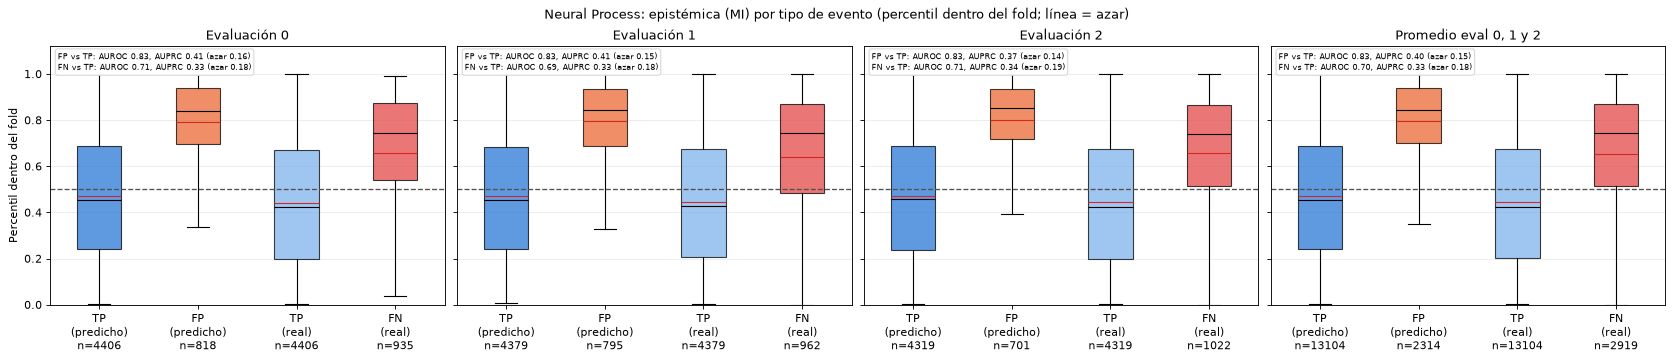

In [8]:
events = results['events']
print('Medianas por tipo de evento')
display(report.event_medians(events))
print('FP vs TP (tramo predicho)')
display(report.event_separation(events, 'TP (predicho)', 'FP (predicho)'))
print('FN vs TP (tramo real)')
display(report.event_separation(events, 'TP (real)', 'FN (real)'))
for figure in report.plot_event_boxes(results, METHOD):
    show(figure)

## 8. Derivar a revisión las detecciones más inciertas

Si se manda a revisión el x% de detecciones con más incertidumbre, ¿qué precisión tiene lo que se acepta automáticamente y qué parte de los falsos positivos se captura?

eval 0
eval 1
eval 2
promedio eval 0, 1 y 2


precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.6            84.6                84.6                0.0             0.0                 0.0
5.0                          86.1            86.3                86.4               14.1            15.5                16.5
10.0                         87.8            88.1                88.5               28.7            30.5                33.3
20.0                         91.0            91.3                91.9               53.3            55.7                58.5
30.0                         93.7            94.0                94.2               71.7            73.3                74.1

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.7            84.7                84.7                0.0             0.0                 0.0
5.0                          86.6            86.5                86.7               16.5            16.0                17.5
10.0                         88.2            88.1                88.4               30.8            30.1                31.8
20.0                         91.4            91.6                92.0               55.2            56.2                58.4
30.0                         94.4            94.0                94.6               74.3            72.7                75.3

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          86.2            86.2                86.2                0.0             0.0                 0.0
5.0                          87.7            87.5                88.0               15.7            14.5                17.4
10.0                         89.4            89.4                89.5               31.7            30.8                31.7
20.0                         92.1            92.8                93.0               54.8            58.0                59.3
30.0                         94.9            95.0                95.7               74.3            74.7                78.2

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          85.2            85.2                85.2                0.0             0.0                 0.0
5.0                          86.8            86.8                87.0               15.4            15.3                17.1
10.0                         88.5            88.5                88.8               30.4            30.5                32.3
20.0                         91.5            91.9                92.3               54.4            56.6                58.7
30.0                         94.3            94.3                94.8               73.4            73.5                75.9

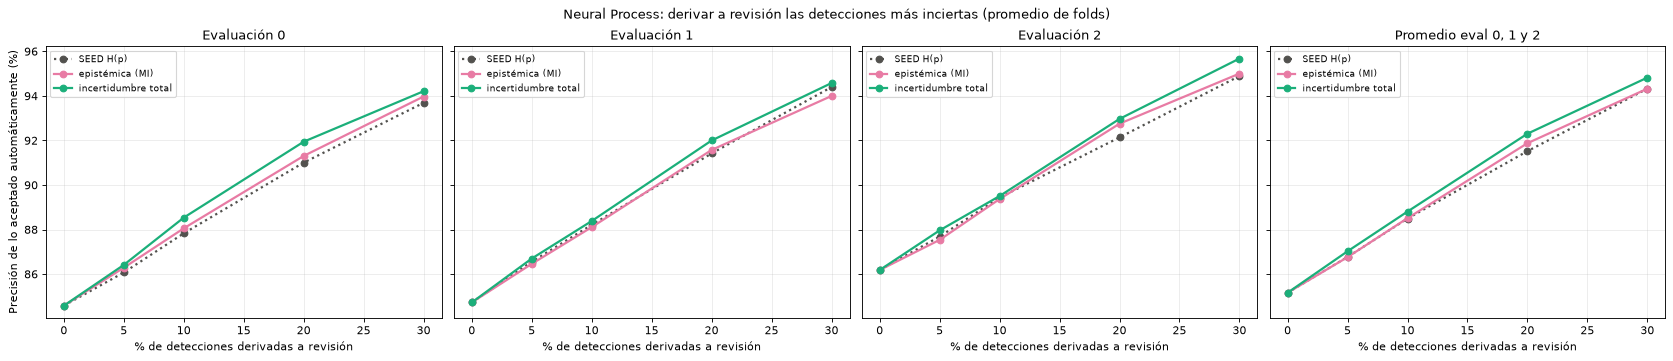

In [9]:
deferral = results['deferral'].dropna(subset=['% derivado'])
for label, part in [(f'eval {e}', deferral[deferral['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE.lower(), deferral)]:
    print(label)
    display(part.groupby(['medida', '% derivado'])[['precisión aceptado (%)', '% de FP capturados']].mean().round(1).unstack('medida'))
show(report.plot_deferral(results, METHOD))

## 9. Descartar automáticamente las detecciones más inciertas

Sin revisión humana: se eliminan las detecciones con mayor incertidumbre (MI; para SEED, entropía). Los aciertos eliminados pasan a ser falsos negativos. Para que el F1 suba, más de ~58% de lo descartado debe ser FP (con F1 ≈ 83%, el equilibrio es 1 − F1/2).

FP descartados  TP descartados  % FP en lo descartado  cambio F1 (puntos)
medida              % descartado                                                                           
SEED H(p)           0.5                     2.73            2.40                  52.33               -0.03
                    1.0                     5.53            4.73                  53.06               -0.05
                    2.0                    10.07           10.53                  48.53               -0.19
                    5.0                    23.53           27.80                  45.39               -0.64
                    10.0                   46.53           56.40                  44.75               -1.38
                    20.0                   83.80          121.80                  40.25               -3.88
epistémica (MI)     0.5                     2.33            2.80                  45.33               -0.06
                    1.0                     4.53            5.73                  44.00               -0.14
                    2.0                     9.13           11.47                  44.04               -0.28
                    5.0                    23.47           27.87                  45.21               -0.65
                    10.0                   46.80           56.13                  44.91               -1.36
                    20.0                   86.73          118.87                  41.68               -3.57
incertidumbre total 0.5                     2.47            2.67                  47.22               -0.05
                    1.0                     5.13            5.13                  49.47               -0.08
                    2.0                    10.20           10.40                  48.98               -0.18
                    5.0                    26.07           25.27                  50.23               -0.40
                    10.0                   49.60           53.33                  47.58               -1.08
                    20.0                   90.47          115.13                  43.39               -3.19

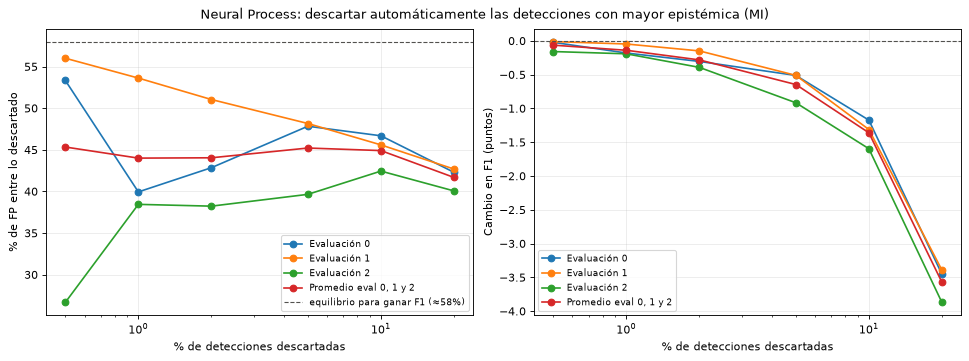

In [10]:
rejection = results['deferral'].dropna(subset=['% descartado'])
display(rejection.groupby(['medida', '% descartado'])[['FP descartados', 'TP descartados', '% FP en lo descartado', 'cambio F1 (puntos)']].mean().round(2))
show(report.plot_rejection(results, METHOD))

## 10. Información del método

Época elegida por early stopping y épocas entrenadas, por fold.

In [11]:
info = results['info']
display(info.set_index(['evaluación', 'fold']).round(3))
display(report.by_evaluation(info))

mejor época  épocas entrenadas
evaluación fold                                
0          0               8                 13
           1               1                  6
           2              11                 16
           3               6                 11
           4               7                 12
1          0              10                 15
           1               2                  7
           2               9                 14
           3               8                 13
           4               6                 11
2          0               8                 13
           1              10                 15
           2               8                 13
           3               8                 13
           4               8                 13

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
mejor época,6.6 ± 3.6,7 ± 3.2,8.4 ± 0.89,7.333 ± 2.7
épocas entrenadas,11.6 ± 3.6,12 ± 3.2,13.4 ± 0.89,12.33 ± 2.7


## Ejemplo temporal

Mismo segmento que el ejemplo de Laplace de la presentación: evaluación 0, fold 1, registro 261, 20 s desde el segundo 60. Paneles: señal EEG con los husos del experto sombreados, etiqueta real, predicción de SEED, predicción de Neural Process y su MI en bits.

In [12]:
import os

import h5py
import numpy as np

from eeg_uq.method_summary import load_fold

DATA_ROOT = Path(os.environ.get('EEG_DATA_ROOT', Path.home() / 'Downloads' / 'data' / 'data'))
SR = 200
EXAMPLE_EVALUATION, EXAMPLE_FOLD, EXAMPLE_SAMPLE, EXAMPLE_START_S = 0, 0, 261, 60
GREEN, BLUE = '#2ca25f', '#2a78d6'

seed_fold = load_fold(report.method_path('SEED', EXAMPLE_EVALUATION, EXAMPLE_FOLD), 'seed')
method_fold = load_fold(report.method_path(METHOD, EXAMPLE_EVALUATION, EXAMPLE_FOLD), 'neural_process')
row = int(np.flatnonzero(method_fold['sample_id'] == EXAMPLE_SAMPLE)[0])
seed_row = int(np.flatnonzero(seed_fold['sample_id'] == EXAMPLE_SAMPLE)[0])
window = slice(EXAMPLE_START_S * SR, (EXAMPLE_START_S + 20) * SR)
with h5py.File(DATA_ROOT / 'moda_moda.h5', 'r') as source:
    signal = np.asarray(source['signals'][EXAMPLE_SAMPLE], dtype=float)[window]
labels = method_fold['y_true'][row][window]
times = np.arange(len(labels)) / SR
mi = method_fold['mi'][row][window]
print(f'MI en el segmento: máximo {mi.max():.4f} bits, media {mi.mean():.4f} bits')

panels = [('SEED\ny_predict', seed_fold['processed_pred'][seed_row][window], 'binario'),
          ('NP\ny_predict', method_fold['processed_pred'][row][window], 'binario'),
          ('NP\nMI (bits)', mi, 'curva')]
fig, axes = plt.subplots(2 + len(panels), 1, figsize=(14, 8.7), sharex=True,
                         gridspec_kw={'height_ratios': [2.6, 0.9, 0.9, 0.9, 0.9]}, constrained_layout=True)
fig.suptitle(f'{METHOD}: detección e incertidumbre — fold {EXAMPLE_FOLD + 1}, registro {EXAMPLE_SAMPLE}, segmento de 20 s')
axes[0].plot(times, signal, color='#263238', lw=0.6)
axes[0].set_ylabel('EEG (µV)')
axes[1].step(times, labels, where='post', color='black', lw=1.2)
axes[1].set(ylabel='y_true', ylim=(-0.1, 1.1))
for ax, (label, values, kind) in zip(axes[2:], panels):
    if kind == 'binario':
        ax.step(times, values, where='post', color=BLUE, lw=1.3)
        ax.set_yticks([0, 1], ['Fondo', 'Evento'])
        ax.set_ylim(-0.1, 1.1)
    else:
        ax.plot(times, values, color='#d81b60', lw=1.2)
    ax.set_ylabel(label)
edges = np.diff(np.r_[0, labels, 0])
for ax in axes:
    for begin, stop in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
        ax.axvspan(times[begin], times[min(stop, len(times) - 1)], color=GREEN, alpha=0.15, lw=0)
    ax.grid(alpha=0.25)
axes[-1].set(xlabel='Tiempo dentro del segmento (s)', xlim=(0, 20))
show(fig)

Salida oculta en el repositorio: muestra señal EEG cruda de los datos privados (MODA).
Ejecuta la celda localmente con los datos para verla.


## Ejemplos temporales por tipo de evento

Segmentos de 20 s centrados en un evento del método (evaluación 0, fold 1), uno por tipo:

- **TP**: el método detectó un huso real.
- **FP**: el método detectó un huso que el experto no marcó.
- **FN**: el experto marcó un huso que el método no detectó.

Para cada tipo se muestran dos casos: uno con **MI alta** (percentil 90 de su tipo) y otro con **MI baja** (percentil 10). Las líneas naranjas punteadas marcan el evento del ejemplo; el verde, los husos del experto. Todos los paneles de MI usan la misma escala para poder compararlos. Solo se consideran eventos de al menos 0,5 s.

In [13]:
PREFIX = 'NP'
EXAMPLE_PERCENTILES = (('MI alta', 0.9), ('MI baja', 0.1))
ORANGE = '#eb6834'
row_of = {int(s): r for r, s in enumerate(method_fold['sample_id'])}
seed_row_of = {int(s): r for r, s in enumerate(seed_fold['sample_id'])}
length = method_fold['y_true'].shape[1]

# MI media de cada evento del método: TP y FP en el tramo predicho, FN en el tramo real.
records = []
for sample, status, p0, p1, t0, t1 in zip(method_fold['event_sample_id'], method_fold['event_status'],
                                          method_fold['event_pred_start'], method_fold['event_pred_end'],
                                          method_fold['event_true_start'], method_fold['event_true_end']):
    if status in ('TP', 'FP'):
        start, end = int(p0), int(p1)
    elif status == 'FN':
        start, end = int(t0), int(t1)
    else:
        continue
    if end - start < SR // 2:
        continue
    row = row_of[int(sample)]
    records.append({'tipo': str(status), 'registro': int(sample), 'inicio': start, 'fin': end,
                    'MI media': float(method_fold['mi'][row, start:end].mean())})
fold_events = pd.DataFrame(records)

examples = []
for kind in ('TP', 'FP', 'FN'):
    group = fold_events[fold_events['tipo'] == kind].sort_values('MI media').reset_index(drop=True)
    for label, quantile in EXAMPLE_PERCENTILES:
        pick = group.iloc[int(round(quantile * (len(group) - 1)))]
        center = (pick['inicio'] + pick['fin']) // 2
        begin = int(np.clip(center - 10 * SR, 0, length - 20 * SR))
        examples.append((kind, label, pick, slice(begin, begin + 20 * SR)))
display(pd.DataFrame([{'tipo': k, 'caso': l, 'registro': p['registro'], 'MI media (bits)': round(p['MI media'], 4),
                       'duración (s)': (p['fin'] - p['inicio']) / SR} for k, l, p, _ in examples]))

mi_max = max(method_fold['mi'][row_of[int(p['registro'])]][w].max() for _, _, p, w in examples) * 1.1
with h5py.File(DATA_ROOT / 'moda_moda.h5', 'r') as source:
    for kind, label, pick, window in examples:
        sample = int(pick['registro'])
        row, seed_row = row_of[sample], seed_row_of[sample]
        signal = np.asarray(source['signals'][sample], dtype=float)[window]
        labels = method_fold['y_true'][row][window]
        times = np.arange(len(labels)) / SR
        focus = ((pick['inicio'] - window.start) / SR, (pick['fin'] - window.start) / SR)
        rows = [('SEED\ny_predict', seed_fold['processed_pred'][seed_row][window]),
                (PREFIX + '\ny_predict', method_fold['processed_pred'][row][window])]
        fig, axes = plt.subplots(5, 1, figsize=(14, 8.2), sharex=True,
                                 gridspec_kw={'height_ratios': [2.4, 0.8, 0.8, 0.8, 1.0]}, constrained_layout=True)
        fig.suptitle(f'{METHOD} · {kind} con {label} (MI media del evento {pick["MI media"]:.3f} bits) — registro {sample}, '
                     f'{window.start / SR:.0f}–{window.stop / SR:.0f} s')
        axes[0].plot(times, signal, color='#263238', lw=0.6)
        axes[0].set_ylabel('EEG (µV)')
        axes[1].step(times, labels, where='post', color='black', lw=1.2)
        axes[1].set(ylabel='y_true', ylim=(-0.1, 1.1))
        for ax, (name, values) in zip(axes[2:4], rows):
            ax.step(times, values, where='post', color=BLUE, lw=1.3)
            ax.set_yticks([0, 1], ['Fondo', 'Evento'])
            ax.set(ylabel=name, ylim=(-0.1, 1.1))
        axes[4].plot(times, method_fold['mi'][row][window], color='#d81b60', lw=1.2)
        axes[4].set(ylabel=PREFIX + '\nMI (bits)', ylim=(0, mi_max))
        edges = np.diff(np.r_[0, labels, 0])
        for ax in axes:
            for begin, stop in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
                ax.axvspan(times[begin], times[min(stop, len(times) - 1)], color=GREEN, alpha=0.15, lw=0)
            for edge in focus:
                ax.axvline(edge, color=ORANGE, ls='--', lw=1.6)
            ax.grid(alpha=0.25)
        axes[-1].set(xlabel='Tiempo dentro del segmento (s)', xlim=(0, 20))
        show(fig)

Salida oculta en el repositorio: muestra señal EEG cruda de los datos privados (MODA).
Ejecuta la celda localmente con los datos para verla.


## Hallazgos

Cifras como eval 0 / eval 1 / eval 2 / promedio de las tres (15 folds de test); un solo número es el promedio.

1. **Mejora el F1, pero empeora la calibración:** F1 83.4% / 83.3% / 83.3% / 83.3% (SEED 82.7%), pero NLL 0.054 / 0.057 / 0.055 / 0.055 contra 0.051 de SEED.
2. **Tiene la incertidumbre epistémica más grande** (23% del total), con una escala propia que no es comparable directamente con la de los métodos bayesianos.
3. **Su MI es la más útil de todos los métodos:** AUROC de errores 0.881 / 0.880 / 0.883 / 0.881 y AUPRC 0.41 (azar 0.10).
4. **Es el método que mejor detecta los dos tipos de error con la MI:** FP vs TP con AUROC 0.83 y AUPRC 0.40 (azar 0.15); **FN vs TP con AUROC 0.71 y AUPRC 0.34 (azar 0.18)**. En los husos perdidos, su MI mediana es ~9 veces la de los aciertos, y su parte aleatoria en ellos es tan baja como en los aciertos: la incertidumbre de los FN es casi toda epistémica.
5. **Su incertidumbre total, en cambio, queda bajo SEED** (0.883 contra 0.894).
6. **El early stopping del fold 1 corta muy temprano** en las evaluaciones 0 y 1 (épocas 1–2), porque la pérdida de validación sin etiquetas es ruidosa; en la evaluación 2 llega a la época 10.

**Conclusión.** Mejor MI de todos, y el único método (con el Deep Ensemble) que detecta parte de los errores silenciosos, a costa de una calibración algo peor.